**2. Crear 01_eda.ipynb y cargar los datos**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

SEMILLA = 42

print("Bibliotecas cargadas correctamente")
print("Semilla:", SEMILLA)

Bibliotecas cargadas correctamente
Semilla: 42


In [2]:
print("Archivos disponibles en /content:")
print(os.listdir("/content"))

Archivos disponibles en /content:
['.config', 'sample_data']


In [4]:
RUTA = "/content/plantvillage_tomate_metadata_auditado.csv"
df = pd.read_csv(RUTA)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (18160, 11)


,image_path,tipo_imagen,clase,crop,disease,particion,image_identifier,existe_en_leaf_map,leaf_id,posible_fuga,particion_auditada
0,raw/color/Tomato___Early_blight/27ba7432-8547-...,color,Tomato___Early_blight,Tomato,Early_blight,train,rs_erly.b 7544,True,Tomato___Early_blight:::76.0,False,train
1,raw/color/Tomato___Early_blight/c78483c5-424f-...,color,Tomato___Early_blight,Tomato,Early_blight,train,rs_erly.b 7541,True,Tomato___Early_blight:::76.0,False,train
2,raw/color/Tomato___Early_blight/289972f1-4f80-...,color,Tomato___Early_blight,Tomato,Early_blight,train,rs_erly.b 7542,True,Tomato___Early_blight:::76.0,False,train
3,raw/color/Tomato___Early_blight/08615b7d-eca7-...,color,Tomato___Early_blight,Tomato,Early_blight,train,rs_erly.b 7543,True,Tomato___Early_blight:::76.0,False,train
4,raw/color/Tomato___Early_blight/cc822ace-0411-...,color,Tomato___Early_blight,Tomato,Early_blight,train,rs_erly.b 7553,True,Tomato___Early_blight:::79.0,False,train


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18160 entries, 0 to 18159
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   image_path          18160 non-null  object
 1   tipo_imagen         18160 non-null  object
 2   clase               18160 non-null  object
 3   crop                18160 non-null  object
 4   disease             18160 non-null  object
 5   particion           18160 non-null  object
 6   image_identifier    18160 non-null  object
 7   existe_en_leaf_map  18160 non-null  bool  
 8   leaf_id             18160 non-null  object
 9   posible_fuga        18160 non-null  bool  
 10  particion_auditada  18160 non-null  object
dtypes: bool(2), object(9)
memory usage: 1.3+ MB


**3. Nulos y duplicados**

In [6]:
def resumen_calidad(tabla):
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "distintos": tabla.nunique()
    })

resumen_calidad(df)

,tipo,nulos,pct_nulos,distintos
image_path,object,0,0.0,18160
tipo_imagen,object,0,0.0,1
clase,object,0,0.0,10
crop,object,0,0.0,1
disease,object,0,0.0,10
particion,object,0,0.0,2
image_identifier,object,0,0.0,18146
existe_en_leaf_map,bool,0,0.0,2
leaf_id,object,0,0.0,9589
posible_fuga,bool,0,0.0,2


In [7]:
print("Filas duplicadas:", df.duplicated().sum())

print("Rutas duplicadas:", df["image_path"].duplicated().sum())

print("Identificadores duplicados:", df["image_identifier"].duplicated().sum())

Filas duplicadas: 0
Rutas duplicadas: 0
Identificadores duplicados: 14


In [8]:
duplicados = df[
    df["image_identifier"].duplicated(keep=False)
].sort_values("image_identifier")

print("Registros con identificadores repetidos:", len(duplicados))

duplicados[[
    "image_path",
    "clase",
    "image_identifier",
    "leaf_id",
    "particion_auditada"
]]

Registros con identificadores repetidos: 28


,image_path,clase,image_identifier,leaf_id,particion_auditada
2053,raw/color/Tomato___healthy/9662364c-aaba-45e3-...,Tomato___healthy,gh_hl leaf 220,fallback_gh_hl leaf 220,train
14909,raw/color/Tomato___healthy/d2ce7896-6fa4-45e6-...,Tomato___healthy,gh_hl leaf 220,fallback_gh_hl leaf 220,train
1600,raw/color/Tomato___healthy/e786ac89-29fe-47e3-...,Tomato___healthy,gh_hl leaf 342.1,fallback_gh_hl leaf 342.1,train
1816,raw/color/Tomato___healthy/37aad83b-7ff8-4b35-...,Tomato___healthy,gh_hl leaf 342.1,fallback_gh_hl leaf 342.1,train
1565,raw/color/Tomato___healthy/505465db-407b-4e0a-...,Tomato___healthy,gh_hl leaf 389,fallback_gh_hl leaf 389,train
2051,raw/color/Tomato___healthy/37203047-d8ba-43f7-...,Tomato___healthy,gh_hl leaf 389,fallback_gh_hl leaf 389,train
1418,raw/color/Tomato___healthy/488feb1c-4b9f-44e7-...,Tomato___healthy,gh_hl leaf 434,fallback_gh_hl leaf 434,train
2335,raw/color/Tomato___healthy/a5de43e7-fc2f-4a14-...,Tomato___healthy,gh_hl leaf 434,fallback_gh_hl leaf 434,train
1464,raw/color/Tomato___healthy/34c81c57-e1fa-49dd-...,Tomato___healthy,gh_hl leaf 466.1,fallback_gh_hl leaf 466.1,train
14886,raw/color/Tomato___healthy/068e324c-faf6-40d6-...,Tomato___healthy,gh_hl leaf 466.1,fallback_gh_hl leaf 466.1,train


In [9]:
print("Distribución de particiones:")
print(df["particion_auditada"].value_counts(dropna=False))

print("\nRegistros con partición vacía:")
print(
    df[
        df["particion_auditada"].isna() |
        (df["particion_auditada"].astype(str).str.strip() == "")
    ][[
        "image_path",
        "clase",
        "image_identifier",
        "leaf_id",
        "particion_auditada"
    ]]
)

Distribución de particiones:
particion_auditada
train    14526
test      3634
Name: count, dtype: int64

Registros con partición vacía:
Empty DataFrame
Columns: [image_path, clase, image_identifier, leaf_id, particion_auditada]
Index: []


In [10]:
particiones_duplicados = (
    duplicados.groupby("image_identifier")["particion_auditada"]
    .nunique()
)

print(
    "Identificadores repetidos presentes en varias particiones:",
    (particiones_duplicados > 1).sum()
)

Identificadores repetidos presentes en varias particiones: 0


**5. Sesgo de muestreo y desequilibrio**

In [11]:
print("Número de imágenes por clase:")
print(df["clase"].value_counts())

print("\nPorcentaje por clase:")
print((df["clase"].value_counts(normalize=True) * 100).round(2))

Número de imágenes por clase:
clase
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Bacterial_spot                          2127
Tomato___Late_blight                             1909
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___healthy                                 1591
Tomato___Target_Spot                             1404
Tomato___Early_blight                            1000
Tomato___Leaf_Mold                                952
Tomato___Tomato_mosaic_virus                      373
Name: count, dtype: int64

Porcentaje por clase:
clase
Tomato___Tomato_Yellow_Leaf_Curl_Virus           29.50
Tomato___Bacterial_spot                          11.71
Tomato___Late_blight                             10.51
Tomato___Septoria_leaf_spot                       9.75
Tomato___Spider_mites Two-spotted_spider_mite     9.23
Tomato___healthy                                  8.76
Tomato___Target_Spot                   

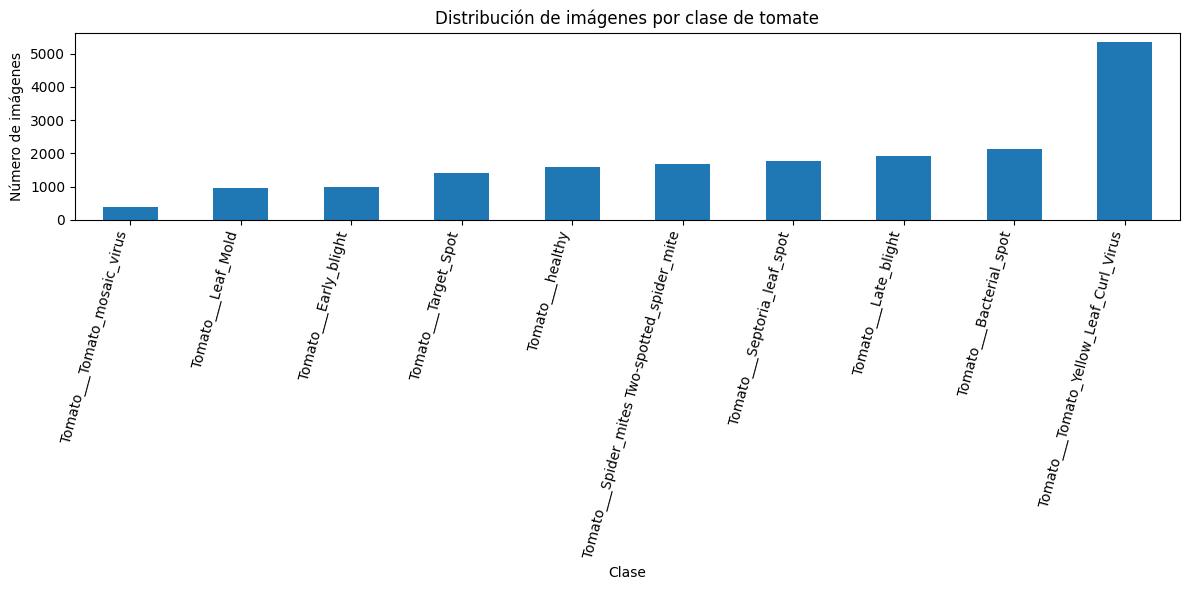

In [12]:
df["clase"].value_counts().sort_values().plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Distribución de imágenes por clase de tomate")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

La distribución de imágenes presenta un desequilibrio entre las 10 clases. La clase Tomato___Tomato_Yellow_Leaf_Curl_Virus es la más representada, con 5.357 imágenes (29,50 %), mientras que Tomato___Tomato_mosaic_virus es la menos representada, con 373 imágenes (2,05 %). Esta diferencia puede provocar que el modelo tenga un rendimiento desigual entre enfermedades. Se conservarán todas las clases y se tendrán en cuenta métricas por clase durante la evaluación.

In [16]:
from huggingface_hub import hf_hub_download

archivo_zip = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="data.zip",
    repo_type="dataset"
)

print("Archivo descargado:", archivo_zip)

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Archivo descargado: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip


In [17]:
import zipfile
import os

with zipfile.ZipFile(archivo_zip, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Extracción completada.")
print("Contenido de /content:")
print(os.listdir("/content"))

Extracción completada.
Contenido de /content:
['.config', 'raw', 'plantvillage_tomate_metadata_auditado.csv', 'sample_data']


In [18]:
from PIL import Image
from collections import Counter
import os

dimensiones = Counter()
errores = 0

for ruta in df["image_path"]:
    ruta_completa = os.path.join("/content", ruta)

    try:
        with Image.open(ruta_completa) as imagen:
            dimensiones[imagen.size] += 1
    except Exception:
        errores += 1

print("Dimensiones encontradas:")
for dimension, cantidad in dimensiones.items():
    print(dimension, ":", cantidad)

print("\nTotal de imágenes analizadas:", sum(dimensiones.values()))
print("Errores de lectura:", errores)

Dimensiones encontradas:
(256, 256) : 18160

Total de imágenes analizadas: 18160
Errores de lectura: 0


Todas las imágenes analizadas presentan dimensiones uniformes de 256 × 256 píxeles. Se han podido abrir y leer las 18.160 imágenes sin errores. Por tanto, no es necesario descartar imágenes por dimensiones incorrectas o problemas de lectura.

In [19]:
formatos = Counter()

for ruta in df["image_path"]:
    ruta_completa = os.path.join("/content", ruta)

    with Image.open(ruta_completa) as imagen:
        formatos[imagen.format] += 1

print("Formatos encontrados:")
for formato, cantidad in formatos.items():
    print(formato, ":", cantidad)

Formatos encontrados:
JPEG : 18160


Las 18.160 imágenes están almacenadas en formato JPEG. No se han detectado formatos diferentes, por lo que existe uniformidad en el formato de los archivos.

In [20]:
modos = Counter()

for ruta in df["image_path"]:
    ruta_completa = os.path.join("/content", ruta)

    with Image.open(ruta_completa) as imagen:
        modos[imagen.mode] += 1

print("Modos de color encontrados:")
for modo, cantidad in modos.items():
    print(modo, ":", cantidad)

Modos de color encontrados:
RGB : 18160


Todas las imágenes utilizan el modo de color RGB. No se han detectado imágenes en escala de grises ni con otros modos de color. Por tanto, los datos presentan uniformidad en este aspecto y están preparados en cuanto a formato, dimensiones y canales de color para su procesamiento mediante redes neuronales convolucionales.

In [23]:
duplicados_imagen.groupby("hash_md5").agg(
    imagenes=("image_path", "count"),
    particiones=("particion_auditada", "nunique"),
    clases=("clase", "nunique")
)

,imagenes,particiones,clases
hash_md5,,,
0e0dcd876f5b32cac9da836b2e783d91,2,1,1
1d87a50fa691cef6f476b20bb48cfaf8,2,1,1
2e53ad1ec3f810e2ff4c83400dc69ec9,2,1,1
32cb22521edc69a5503a6749446dd522,2,1,1
3b227920ba50ce0a4602b258f624e935,2,1,1
3dab5eb1192b5c43fd3015490cf0b18f,2,1,1
4b73700b68ce8704f6b4549a2846dede,2,1,1
4bab4aa40d89e19ed72d8b8d501b1db8,2,1,1
5bdbdc7333be3ab35ef81ec17ce14816,2,1,1


Duplicados: No se detectaron filas ni rutas duplicadas. Sin embargo, mediante una comprobación de hash MD5 se identificaron 14 imágenes duplicadas exactas, cada una presente dos veces. Todas las parejas pertenecen a la misma clase y a una única partición (entrenamiento o test). No se detectaron cruces entre particiones. Se conservan los registros y se documenta el hallazgo.

**Comprobar valores y rutas**

In [24]:
rutas_existen = df["image_path"].apply(
    lambda ruta: os.path.isfile(os.path.join("/content", ruta))
)

print("Rutas existentes:", rutas_existen.sum())
print("Rutas inexistentes:", (~rutas_existen).sum())

Rutas existentes: 18160
Rutas inexistentes: 0


**Eliminar duplicados exactos del conjunto de trabajo**

In [25]:
df_sin_duplicados = df.drop_duplicates(
    subset="hash_md5",
    keep="first"
).copy()

print("Imágenes originales:", len(df))
print("Imágenes después de limpiar:", len(df_sin_duplicados))
print("Duplicados eliminados:", len(df) - len(df_sin_duplicados))

Imágenes originales: 18160
Imágenes después de limpiar: 18146
Duplicados eliminados: 14


**Verificar el conjunto limpio**

In [26]:
print("CLASES:")
print(df_sin_duplicados["clase"].nunique())

print("\nIMÁGENES POR PARTICIÓN:")
print(df_sin_duplicados["particion_auditada"].value_counts())

print("\nIMÁGENES POR CLASE:")
print(df_sin_duplicados["clase"].value_counts())

CLASES:
10

IMÁGENES POR PARTICIÓN:
particion_auditada
train    14512
test      3634
Name: count, dtype: int64

IMÁGENES POR CLASE:
clase
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Bacterial_spot                          2127
Tomato___Late_blight                             1901
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___healthy                                 1585
Tomato___Target_Spot                             1404
Tomato___Early_blight                            1000
Tomato___Leaf_Mold                                952
Tomato___Tomato_mosaic_virus                      373
Name: count, dtype: int64


Limpieza de duplicados: Se identificaron 14 imágenes duplicadas exactas mediante hash MD5. Se conservó una copia de cada imagen y se eliminaron las 14 repeticiones del conjunto de trabajo. Tras la limpieza quedaron 18.146 imágenes distribuidas en 10 clases. Se mantienen las particiones originales, con 14.512 imágenes de entrenamiento y 3.634 de test.

**Analizar la distribución de las particiones por clase**

In [27]:
pd.crosstab(
    df_sin_duplicados["clase"],
    df_sin_duplicados["particion_auditada"]
)

particion_auditada,test,train
clase,,
Tomato___Bacterial_spot,436,1691
Tomato___Early_blight,215,785
Tomato___Late_blight,372,1529
Tomato___Leaf_Mold,172,780
Tomato___Septoria_leaf_spot,337,1434
Tomato___Spider_mites Two-spotted_spider_mite,320,1356
Tomato___Target_Spot,288,1116
Tomato___Tomato_Yellow_Leaf_Curl_Virus,1100,4257
Tomato___Tomato_mosaic_virus,66,307


Se ha comprobado la distribución de las clases en las particiones de entrenamiento y test. Las diez clases están representadas en ambos conjuntos. La distribución global se mantiene aproximadamente en un 80 % para entrenamiento y un 20 % para test. Se conserva el test reservado para la evaluación final.

**Distribución por partición**

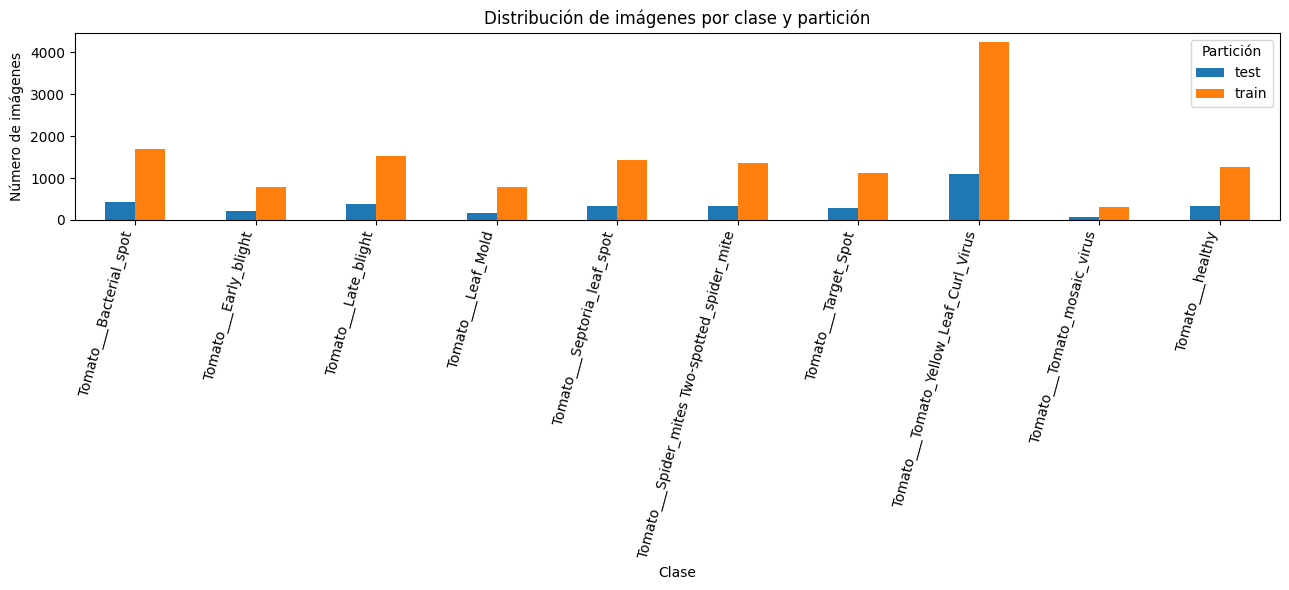

In [28]:
pd.crosstab(
    df_sin_duplicados["clase"],
    df_sin_duplicados["particion_auditada"]
).plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Distribución de imágenes por clase y partición")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Partición")
plt.tight_layout()
plt.show()

El gráfico muestra la distribución de imágenes por clase en los conjuntos de entrenamiento y test. Todas las clases están presentes en ambas particiones, manteniendo una proporción aproximada del 80 % para entrenamiento y del 20 % para test. Se observa que el desequilibrio entre clases también se mantiene en ambas particiones.

**Porcentaje de cada clase**

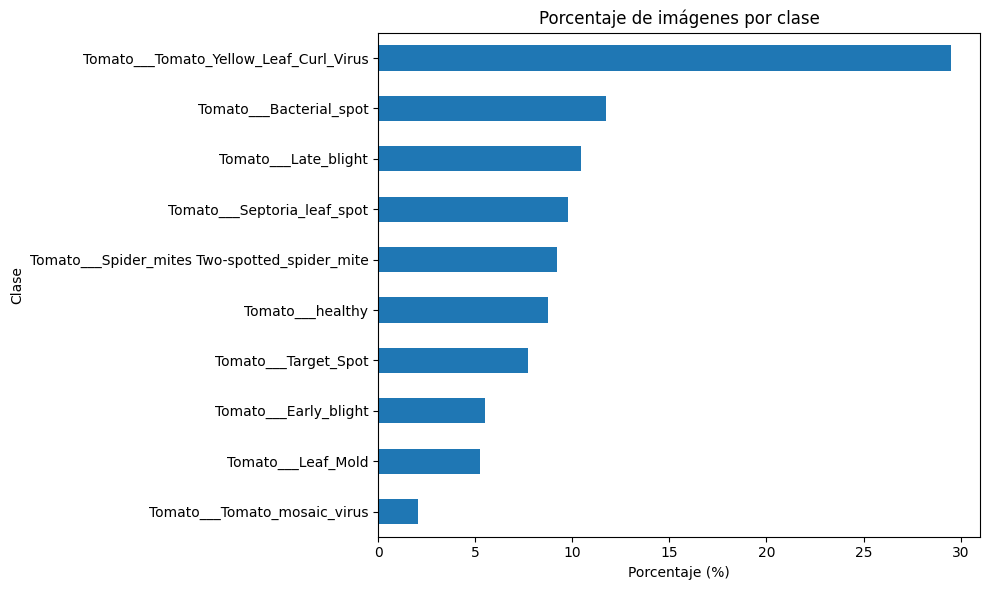

In [29]:
(df_sin_duplicados["clase"].value_counts(normalize=True) * 100).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Porcentaje de imágenes por clase")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Clase")
plt.tight_layout()
plt.show()

El gráfico muestra que la distribución de imágenes no es equilibrada. La clase Tomato Yellow Leaf Curl Virus concentra aproximadamente el 29,5 % de las imágenes, mientras que Tomato mosaic virus representa alrededor del 2 %. Este desequilibrio puede afectar al aprendizaje del modelo, por lo que será necesario analizar el rendimiento individual de cada clase y no utilizar únicamente la exactitud global.

**7. Revisar posibles fugas de datos**

In [30]:
print("Auditoría de posibles fugas:")
print(df_sin_duplicados["posible_fuga"].value_counts())

print("\nCorrespondencia con leaf-map:")
print(df_sin_duplicados["existe_en_leaf_map"].value_counts())

Auditoría de posibles fugas:
posible_fuga
False    18141
True         5
Name: count, dtype: int64

Correspondencia con leaf-map:
existe_en_leaf_map
True     11411
False     6735
Name: count, dtype: int64


**Fugas posibles**: Se han revisado las columnas del conjunto de datos y se ha determinado que los metadatos de identificación, partición y auditoría no deben utilizarse como variables de entrada del modelo. Las columnas clase y disease contienen la información objetivo y tampoco deben utilizarse como entrada. Se han detectado 5 registros marcados como posibles fugas en entrenamiento. Además, el 37,16 % de las imágenes no tiene correspondencia en el leaf-map, por lo que no se puede garantizar completamente la separación por hoja. Se mantendrá esta limitación documentada y se evitará utilizar los identificadores como características predictoras.

**Investigar los cinco registros**

In [31]:
df_sin_duplicados[
    df_sin_duplicados["posible_fuga"] == True
][[
    "image_path",
    "clase",
    "image_identifier",
    "leaf_id",
    "particion_auditada"
]]

,image_path,clase,image_identifier,leaf_id,particion_auditada
1464,raw/color/Tomato___healthy/34c81c57-e1fa-49dd-...,Tomato___healthy,gh_hl leaf 466.1,fallback_gh_hl leaf 466.1,train
2053,raw/color/Tomato___healthy/9662364c-aaba-45e3-...,Tomato___healthy,gh_hl leaf 220,fallback_gh_hl leaf 220,train
13887,raw/color/Tomato___Late_blight/3fae9c64-18f0-4...,Tomato___Late_blight,ghlb_ps leaf 24 day 16,fallback_ghlb_ps leaf 24 day 16,train
14396,raw/color/Tomato___Late_blight/e5d707cd-077c-4...,Tomato___Late_blight,ghlb2 leaf 8999,fallback_ghlb2 leaf 8999,train
14405,raw/color/Tomato___Late_blight/48c55974-9fe9-4...,Tomato___Late_blight,ghlb_ps leaf 23.7 day 13,fallback_ghlb_ps leaf 23.7 day 13,train


Fuga potencial: Se identificaron cinco registros marcados como posibles fugas. Todos pertenecen al conjunto de entrenamiento y utilizan identificadores de respaldo (fallback_). No se han encontrado estos registros en test. Además, el 37,16 % de las imágenes no tiene correspondencia en el leaf-map oficial, por lo que no es posible garantizar completamente la ausencia de fugas entre imágenes de una misma planta. Esta limitación se tendrá en cuenta al interpretar los resultados de los modelos.

**Resumen final del EDA**

In [32]:
print("RESUMEN FINAL DEL EDA")
print("----------------------")

print("Total de imágenes:", len(df_sin_duplicados))
print("Número de clases:", df_sin_duplicados["clase"].nunique())

print("\nDistribución de particiones:")
print(df_sin_duplicados["particion_auditada"].value_counts())

print("\nImágenes por clase:")
print(df_sin_duplicados["clase"].value_counts())

print("\nValores nulos:", df_sin_duplicados.isna().sum().sum())

print("Duplicados exactos restantes:",
      df_sin_duplicados["hash_md5"].duplicated().sum())

RESUMEN FINAL DEL EDA
----------------------
Total de imágenes: 18146
Número de clases: 10

Distribución de particiones:
particion_auditada
train    14512
test      3634
Name: count, dtype: int64

Imágenes por clase:
clase
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Bacterial_spot                          2127
Tomato___Late_blight                             1901
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___healthy                                 1585
Tomato___Target_Spot                             1404
Tomato___Early_blight                            1000
Tomato___Leaf_Mold                                952
Tomato___Tomato_mosaic_virus                      373
Name: count, dtype: int64

Valores nulos: 0
Duplicados exactos restantes: 0
